# ELS 헤지 프로젝트: 코스피200·HSCEI 스텝다운 ELS의 가격, 헤지, 손익 요인 분해

**목표 (FRM Part 1 + 장외파생·ELS 데스크 준비)**
1. 두 지수(코스피200, 홍콩 H지수 = HSCEI) 스텝다운 ELS의 가격을 몬테카를로로 매긴다.
2. 투자자에게 보여 줘야 할 **수익률 모의실험**(조기상환·만기·손실 확률)을 만든다.
3. 발행사가 선물로 델타 헤지할 때 하루하루 손익을 **델타·감마·베가·세타·금리·잔차**로 나눠 설명한다.
4. H지수가 크게 빠진 경로에서 투자자와 발행사에게 무슨 일이 생기는지 보고, 2024년 H지수 ELS 사태와 연결한다.

**자료와 가정** (실제 값과 **[예시]**를 구분합니다)
| 항목 | 값 | 근거 |
|---|---|---|
| 코스피200, VKOSPI | 자료를 받은 시점의 현재가(아래 출력에 조회 시각) | 한국거래소 지수 사이트(`data/krx_idx_*.json`) |
| 원화 할인 금리 | 국고채 3년(반기 복리 → 연속 복리로 환산) | 한국은행 ECOS. 발행사 조달 금리 대신 쓴 **[근사]** |
| HSCEI 수준·변동성, 상관계수, 배당, 환율 관련 값 | 아래 표 | 무료 공식 시계열을 찾지 못해 **[예시]** |
| 상품 조건 | 3년, 6개월마다 조기상환(90-90-85-85-80-75), 연 7%, 낙인 50% | 국내에서 흔한 구조를 본뜬 **[예시]**(실제 상품 아님) |
| H지수 ELS 사태 사실관계 | 금융감독원 보도자료 2024-03-11, 2026-11-04 | `data/fss_hscei_els_20240311.html`, `data/fss_hscei_els_sanction.html` |

**모형**: 위험중립 상관 기하 브라운 운동, 하루 1단계(연 252단계), 낙인은 매일 종가로 확인, 금리·변동성 상수. 계산 코드는 `notebooks/els.py`에 있습니다(직접 읽어 보세요).

In [1]:
import numpy as np
import pandas as pd
import QuantLib as ql
import matplotlib.pyplot as plt
import marketdata as md
import els

today = ql.Date(10, ql.November, 2026)
ql.Settings.instance().evaluationDate = today
cal = md.krx_calendar(ql.SouthKorea.Settlement)
k200, vkospi = md.krx_index("코스피 200"), md.krx_index("코스피 200 변동성지수")
day_k, ktb = md.ktb_yields()
r_cont = ql.InterestRate(ktb[3], ql.Actual365Fixed(), ql.Compounded, ql.Semiannual).equivalentRate(
    ql.Continuous, ql.Annual, 3.0).rate()
prod = els.StepDown()
rho_hfx, vol_fx = 0.3, 0.08                                     # [예시] HSCEI와 원/홍콩달러 환율의 상관, 환율 변동성
mkt = els.Market(r=r_cont, q=(0.015, 0.035), vol=(0.30, 0.30), rho=0.6, quanto=(0.0, rho_hfx * 0.30 * vol_fx))
obs_dates = [cal.adjust(today + ql.Period(6 * (i + 1), ql.Months), ql.Following) for i in range(len(prod.barriers))]
krx_at = md.manifest("krx_idx_representative")["fetched_at_kst"]
print(f"발행일 {today}, 코스피200 {k200:,.2f}, VKOSPI {vkospi:.2f} (KRX 조회 {krx_at}), 국고 3년 {ktb[3]:.3%} → 연속 복리 {r_cont:.4%}")
print(pd.DataFrame({"평가일(KRX 달력)": [str(d) for d in obs_dates], "상환 조건(최초 대비)": [f"{b:.0%}" for b in prod.barriers],
                    "상환 시 수익률": [f"{prod.coupon * (i + 1) / 2:.1%}" for i in range(len(prod.barriers))]},
                   index=[f"{i + 1}차" for i in range(len(prod.barriers))]).to_string())
print(f"낙인 {prod.ki:.0%}: 만기까지 한 번이라도 두 지수 중 하나가 최초의 50% 아래로 마감하면 '낙인'")
print("만기: 마지막 조건(75%)을 못 넘어도 낙인이 없었으면 원금 + 21%, 낙인이 있었으면 원금 × (더 많이 빠진 지수의 비율)")

발행일 November 10th, 2026, 코스피200 778.35, VKOSPI 63.93 (KRX 조회 2026-11-09 18:00:23 KST), 국고 3년 3.639% → 연속 복리 3.6063%
            평가일(KRX 달력) 상환 조건(최초 대비) 상환 시 수익률
1차       May 10th, 2027          90%     3.5%
2차  November 10th, 2027          90%     7.0%
3차       May 10th, 2028          85%    10.5%
4차  November 10th, 2028          85%    14.0%
5차       May 10th, 2029          80%    17.5%
6차  November 12th, 2029          75%    21.0%
낙인 50%: 만기까지 한 번이라도 두 지수 중 하나가 최초의 50% 아래로 마감하면 '낙인'
만기: 마지막 조건(75%)을 못 넘어도 낙인이 없었으면 원금 + 21%, 낙인이 있었으면 원금 × (더 많이 빠진 지수의 비율)


## 1. 가격과 발행 마진
공통 난수 10,000개 경로(5,000쌍, antithetic)로 가격을 매깁니다. 원금 100 기준 가치가 100보다 낮은 만큼이 발행사 쪽 몫(헤지 비용·운영비·이익)입니다.

In [2]:
z = els.normals(5000, prod.n_steps)
v0, se0 = els.price(prod, mkt, z=z)
print(f"ELS 가치 {v0:.3f} (표준오차 {se0:.3f}), 원금 100 대비 {100 - v0:.2f} 낮음 → 100억 원 발행이면 약 {(100 - v0) * 1e8:,.0f}원")
rows = []
for vk in (0.20, 0.30, 0.40, vkospi / 100):
    v, s = els.price(prod, els.Market(r=mkt.r, q=mkt.q, vol=(vk, mkt.vol[1]), rho=mkt.rho, quanto=mkt.quanto), z=z)
    rows.append((f"{vk:.0%}" + (" (오늘 VKOSPI)" if vk == vkospi / 100 else ""), round(v, 3)))
for rho_ in (0.3, 0.8):
    rows.append((f"상관 {rho_} (변동성 30%)", round(els.price(prod, els.Market(r=mkt.r, q=mkt.q, vol=mkt.vol, rho=rho_, quanto=mkt.quanto), z=z)[0], 3)))
print(pd.DataFrame(rows, columns=["코스피200 변동성 / 상관", "ELS 가치"]).to_string(index=False))

ELS 가치 90.752 (표준오차 0.230), 원금 100 대비 9.25 낮음 → 100억 원 발행이면 약 924,777,413원


 코스피200 변동성 / 상관  ELS 가치
             20%  93.876
             30%  90.752
             40%  86.521
 64% (오늘 VKOSPI)  76.999
상관 0.3 (변동성 30%)  88.931
상관 0.8 (변동성 30%)  92.424


읽는 법: 변동성이 오르면 ELS 가치가 떨어집니다. 투자자는 '지수가 크게 빠지지 않는다'에 돈을 거는, 즉 **변동성을 판(short vol)** 쪽입니다. 상관이 낮을수록 둘 중 하나가 빠질 가능성이 커져(worst-of) 가치가 떨어집니다.
오늘 VKOSPI(30일 내재 변동성)를 3년짜리 상품에 그대로 넣으면 과하게 낮은 가치가 나옵니다. 실무에서는 만기별 변동성(기간 구조)을 씁니다.

## 2. 투자자 수익률 모의실험
금융감독원은 2026-11-04 보도참고자료에서 은행들의 위반 내용으로 **'수익률 모의실험 결과 누락 등으로 설명의무 위반'**과 적합성 원칙 위반을 들었습니다(`data/fss_hscei_els_sanction.html`).
아래 표가 그 '모의실험'의 기본형입니다. 위험중립 확률(가격 계산용)과, 주가가 연 4%p 더 오른다고 가정한 확률 **[예시]**을 함께 보입니다. 둘 다 '예측'이 아니라 가정에 따른 계산입니다.

In [3]:
def outcome_table(m, label):
    pv, out, worst = els.pv_paths(prod, m, (1.0, 1.0), 0, False, z)
    n = len(out)
    rows = [(f"{k + 1}차 조기상환", (out == k).mean(), prod.coupon * (k + 1) / 2) for k in range(len(prod.barriers))]
    rows.append(("만기 상환(낙인 없음)", (out == 99).mean(), prod.coupon * prod.years))
    loss = out == 100
    rows.append(("만기 손실(낙인 + 75% 미만)", loss.mean(), (worst[loss, -1] - 1).mean() if loss.any() else 0.0))
    return pd.DataFrame(rows, columns=["결과", f"확률({label})", "수익률(손실이면 평균)"])
rn = outcome_table(mkt, "위험중립")
rw = outcome_table(els.Market(r=mkt.r + 0.04, q=mkt.q, vol=mkt.vol, rho=mkt.rho, quanto=mkt.quanto), "주가 +4%p 예시")
sim = rn.merge(rw[["결과", "확률(주가 +4%p 예시)"]], on="결과")[["결과", "확률(위험중립)", "확률(주가 +4%p 예시)", "수익률(손실이면 평균)"]]
print(sim.to_string(index=False, formatters={c: "{:.1%}".format for c in sim.columns[1:]}))

                결과 확률(위험중립) 확률(주가 +4%p 예시) 수익률(손실이면 평균)
           1차 조기상환    52.3%          56.5%         3.5%
           2차 조기상환     9.6%          10.1%         7.0%
           3차 조기상환     6.6%           6.8%        10.5%
           4차 조기상환     3.2%           3.4%        14.0%
           5차 조기상환     2.9%           3.2%        17.5%
           6차 조기상환     2.7%           2.7%        21.0%
      만기 상환(낙인 없음)     3.3%           2.8%        21.0%
만기 손실(낙인 + 75% 미만)    19.4%          14.5%       -55.4%


읽는 법: 절반 이상은 1차(6개월)에 연 7%(6개월치 3.5%)로 끝나지만, 손실 구간에 들어가면 평균 손실이 원금의 절반 안팎입니다. '확률은 낮지만 손실은 큰' 구조라 평균 수익률만 보여 주면 위험이 가려집니다.
판매 때 이 표(그리고 과거 구간을 넣은 백테스트)를 보여 주고, 투자자가 '최대 원금 전액 손실'을 감당할 수 있는지(적합성) 확인하는 것이 핵심입니다.

## 3. 발행 시점 그릭스
단위: 원금 100 기준. delta·gamma는 '최초 대비 비율'(1.0 = 100%) 1단위당, vega는 변동성 1%p당, rho는 금리 1bp당, theta는 하루당입니다.
delta는 지수를 ±1% 움직여, gamma는 ±5% 움직여 구합니다. 조기상환·낙인 조건이 계단 모양이라 작은 움직임으로 구한 gamma는 몬테카를로 잡음이 커서 부호까지 흔들리기 때문입니다(직접 h를 바꿔 확인해 보세요).
100억 원 발행이면 delta × 1억 원이 '지수 1단위(100%) 움직일 때 손익', 곧 헤지해야 할 지수 노출 금액입니다.

In [4]:
g0 = els.greeks(prod, mkt, (1.0, 1.0), 0, False, z)
print(pd.DataFrame({"코스피200": [g0["delta"][0], g0["gamma"][0], g0["vega"][0]], "HSCEI": [g0["delta"][1], g0["gamma"][1], g0["vega"][1]]},
                   index=["delta", "gamma", "vega(1%p)"]).round(3).to_string())
print(f"cross gamma {g0['cross']:.2f}, rho(1bp) {g0['rho']:.4f}, theta(하루) {g0['theta']:.4f}")
print(f"→ 100억 원 발행 시 발행사(ELS 매도) 헤지: 코스피200 약 {g0['delta'][0]:,.1f}억 원어치, HSCEI 약 {g0['delta'][1]:,.1f}억 원어치 매수(선물)")

            코스피200    HSCEI
delta       29.722   35.566
gamma     -142.488 -209.744
vega(1%p)   -0.418   -0.446
cross gamma 42.09, rho(1bp) -0.0082, theta(하루) 0.0919
→ 100억 원 발행 시 발행사(ELS 매도) 헤지: 코스피200 약 29.7억 원어치, HSCEI 약 35.6억 원어치 매수(선물)


읽는 법: 투자자(ELS 매수)는 두 지수에 대해 delta가 양수이고 gamma·vega가 음수입니다(풋을 판 것과 비슷). 발행사는 반대 포지션이므로 선물을 사서 delta를 맞추고, 남는 gamma·vega 위험을 관리합니다.

## 4. 낙인 근처에서 delta가 어떻게 변하나
발행 1.5년 뒤, 코스피200은 최초 수준, 낙인 미발생일 때 HSCEI 수준별 HSCEI delta를 봅니다.

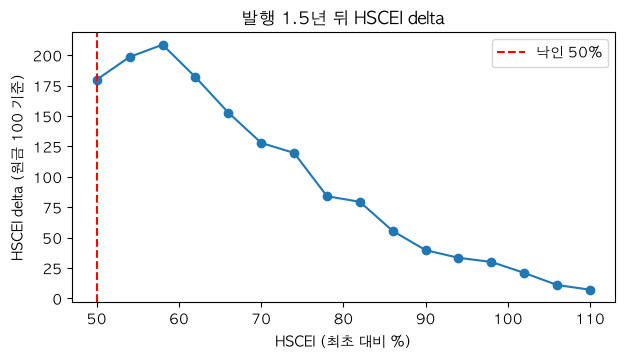

delta가 가장 큰 HSCEI 수준: 58%, 그때 delta 208.6 (HSCEI 102%에서는 20.9)


In [5]:
mid = prod.n_steps // 2
levels = np.round(np.arange(0.50, 1.11, 0.04), 2)
delta_h = [els.greeks(prod, mkt, (1.0, float(x)), mid, False, z)["delta"][1] for x in levels]
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(levels * 100, delta_h, marker="o")
ax.axvline(prod.ki * 100, color="red", ls="--", label="낙인 50%")
ax.set_xlabel("HSCEI (최초 대비 %)")
ax.set_ylabel("HSCEI delta (원금 100 기준)")
ax.set_title("발행 1.5년 뒤 HSCEI delta")
ax.legend()
plt.show()
peak = float(levels[int(np.argmax(delta_h))])
print(f"delta가 가장 큰 HSCEI 수준: {peak:.0%}, 그때 delta {max(delta_h):.1f} (HSCEI 102%에서는 {delta_h[list(levels).index(1.02)]:.1f})")

읽는 법: HSCEI가 낙인 수준에 가까워질수록 delta가 커집니다. 낙인을 맞으면 투자자 손실이 지수에 1:1로 묶이기 때문입니다. 이 구간에서는 지수가 조금만 움직여도 헤지 수량을 크게 바꿔야 해서(큰 gamma) 발행사 헤지 비용과 시장 충격이 커집니다.
많은 ELS가 같은 지수·비슷한 낙인 수준에 몰려 있으면, 지수 하락 때 발행사들이 한꺼번에 선물을 더 사거나 팔아야 하는 일이 생깁니다.

## 5. 10영업일 델타 헤지 시뮬레이션과 손익 요인 분해 **[예시 경로]**
발행사는 100억 원어치 ELS를 팔고, 매일 장 마감에 delta만큼 선물을 맞춥니다. 시장 경로는 **[예시]**입니다: 코스피200은 변동성 30%로 무작위, HSCEI는 하루 평균 −1.5%씩 빠지는 매도세,
5일째 HSCEI 내재 변동성 +5%p, 7일째 원화 금리 +10bp. 매일 '실제 가치 변화'를 그 전날 그릭스로 나눠 설명하고, 설명되지 않는 부분을 잔차로 둡니다.
$$\Delta V \approx \sum_i \delta_i \Delta p_i + \tfrac12 \sum_i \Gamma_i \Delta p_i^2 + \Gamma_{12}\Delta p_1 \Delta p_2 + \sum_i \nu_i \Delta\sigma_i + \rho\,\Delta r + \theta\,\Delta t + \text{잔차}$$

In [6]:
rng = np.random.default_rng(7)
dt = 1 / prod.steps_per_year
perf, elapsed, ki_hit, m_t = (1.0, 1.0), 0, False, mkt
scale = 1e10 / 100                                                # 100억 원 발행, 원금 100 기준 → 원
recs = []
for day in range(1, 11):
    g = els.greeks(prod, m_t, perf, elapsed, ki_hit, z)
    eK = rng.standard_normal()
    eH = m_t.rho * eK + np.sqrt(1 - m_t.rho ** 2) * rng.standard_normal()
    new = (perf[0] * np.exp(-0.5 * 0.30 ** 2 * dt + 0.30 * np.sqrt(dt) * eK),
           perf[1] * np.exp(-0.015 + 0.30 * np.sqrt(dt) * eH))
    m_new = els.Market(r=m_t.r + (1e-3 if day == 7 else 0.0), q=m_t.q,
                       vol=(m_t.vol[0], m_t.vol[1] + (0.05 if day == 5 else 0.0)), rho=m_t.rho, quanto=m_t.quanto)
    ki_new = ki_hit or min(new) < prod.ki
    v_new = els.price(prod, m_new, new, elapsed + 1, ki_new, z)[0]
    dp = (new[0] - perf[0], new[1] - perf[1])
    parts = {"delta": g["delta"][0] * dp[0] + g["delta"][1] * dp[1],
             "gamma": 0.5 * g["gamma"][0] * dp[0] ** 2 + 0.5 * g["gamma"][1] * dp[1] ** 2 + g["cross"] * dp[0] * dp[1],
             "vega": sum(g["vega"][i] * (m_new.vol[i] - m_t.vol[i]) / 0.01 for i in range(2)),
             "rho": g["rho"] * (m_new.r - m_t.r) / 1e-4,
             "theta": g["theta"]}
    dV = v_new - g["value"]
    hedge = sum(g["delta"][i] * (dp[i] - (m_t.r - m_t.q[i] - m_t.quanto[i]) * perf[i] * dt) for i in range(2))
    recs.append(dict(day=day, K200=new[0], HSCEI=new[1], dV=dV, **parts, resid=dV - sum(parts.values()),
                     unhedged=-dV, hedged=-dV + hedge))
    perf, elapsed, ki_hit, m_t = new, elapsed + 1, ki_new, m_new
pnl = pd.DataFrame(recs).set_index("day")
show = pnl[["K200", "HSCEI"]].map(lambda x: f"{x:.1%}").join((pnl[["dV", "delta", "gamma", "vega", "rho", "theta", "resid", "unhedged", "hedged"]] * scale / 1e6).round(1))
print("단위: 백만 원(ELS 가치 변화 dV는 투자자 쪽 기준, unhedged/hedged는 발행사 손익)")
print(show.to_string())
tot = (pnl[["dV", "delta", "gamma", "vega", "rho", "theta", "resid", "unhedged", "hedged"]].sum() * scale / 1e6).round(1)
print("10일 합계(백만 원):", tot.to_dict())

단위: 백만 원(ELS 가치 변화 dV는 투자자 쪽 기준, unhedged/hedged는 발행사 손익)
       K200  HSCEI     dV  delta  gamma   vega  rho  theta  resid  unhedged  hedged
day                                                                                
1    100.0%  99.0%  -31.0  -37.5   -1.1    0.0 -0.0    9.2   -1.6      31.0    -6.7
2     99.5%  95.9% -137.0 -133.1  -12.6    0.0  0.0    8.4    0.3     137.0     3.7
3     98.6%  92.6% -159.4 -181.6   -8.9    0.0 -0.0    5.7   25.3     159.4   -22.2
4     98.7%  93.1%   36.8   30.9   -0.3    0.0  0.0    3.5    2.7     -36.8    -6.0
5     97.7%  90.4% -424.3 -154.4   -4.2 -283.4  0.0    5.6   12.1     424.3   269.8
6     98.6%  90.0%    5.4    1.8   -1.0    0.0  0.0   11.5   -6.9      -5.4    -3.7
7     98.8%  87.5% -127.3 -124.7   -4.7    0.0 -3.0   12.2   -7.0     127.3     2.5
8     98.7%  87.1%  -27.0  -26.9   -0.1    0.0  0.0    0.7   -0.6      27.0    -0.0
9     96.2%  83.9% -243.2 -242.0   -5.2    0.0  0.0   24.8  -20.8     243.2     1.1
10    92.8%  79.4%

읽는 법:
- **dV**(투자자 기준 ELS 가치 변화)는 대부분 **delta** 항으로 설명됩니다. HSCEI가 빠지는 날마다 가치가 떨어집니다.
- 발행사가 헤지하지 않으면(unhedged) 투자자 손실만큼 이익을 보지만, 반대로 지수가 오르면 그만큼 손해를 봅니다. 헤지하면(hedged) 하루 손익이 **gamma·vega·theta·잔차** 크기로 줄어듭니다.
- 5일째 변동성 상승은 ELS 가치를 떨어뜨리므로(투자자 vega < 0) 발행사에게는 이익(발행사는 변동성을 산 쪽)입니다. 7일째 금리 상승은 rho 항으로 보입니다.
- 잔차는 큰 움직임에서의 고차 효과와 몬테카를로 잡음입니다. 면접에서 '헤지 손익을 요인별로 나눠 설명하라'는 질문에 이 표 구조로 답할 수 있습니다.

## 6. H지수가 크게 빠진 경로 **[예시 경로]** 와 2024년 H지수 ELS 사태
금융감독원 2024-03-11 보도자료(`data/fss_hscei_els_20240311.html`)에 따르면, 금감원은 H지수 기초 ELS의 대규모 손실과 관련해 2024-01-08부터 11개 주요 판매사를 현장검사했고,
판매정책·소비자보호 관리 부실, 판매시스템 차원의 불완전판매, 개별 판매과정의 불완전판매를 확인했다고 밝혔습니다. 2026-11-04 보도참고자료에서는 금융위원회가 7개 은행에 과징금 3,619.60억 원·과태료 17.78억 원,
6개 증권사에 과징금 92.82억 원·과태료 16.12억 원을 최종 의결했다고 밝혔습니다(`data/fss_hscei_els_sanction.html`).
아래는 실제 지수 값이 아닌 **[예시 경로]**로, 'HSCEI가 2년에 걸쳐 절반 넘게 빠졌다가 만기에 일부 회복'하는 모양입니다.

In [7]:
t_idx = np.arange(1, prod.n_steps + 1) / prod.steps_per_year
h_path = np.where(t_idx <= 2.0, 1.0 - 0.55 * t_idx / 2.0, 0.45 + 0.15 * (t_idx - 2.0))   # 2년 뒤 45%, 만기 60%
k_path = np.full_like(h_path, 1.0)
worst_s = np.minimum(k_path, h_path)
obs_hit = [k for k, (s, b) in enumerate(zip(prod.obs_steps, prod.barriers)) if worst_s[s - 1] >= b]
ki_s = worst_s.min() < prod.ki
pay_s = prod.notional * (1 + prod.coupon * (obs_hit[0] + 1) / 2) if obs_hit else (
    prod.notional * worst_s[-1] if ki_s else prod.notional * (1 + prod.coupon * prod.years))
first_ki = float(t_idx[np.argmax(worst_s < prod.ki)]) if ki_s else None
print(f"조기상환: {'없음' if not obs_hit else f'{obs_hit[0] + 1}차'}, 낙인: {'발생(약 ' + f'{first_ki:.2f}년 뒤)' if ki_s else '없음'}, "
      f"만기 HSCEI {h_path[-1]:.0%} → 투자자 받는 돈 {pay_s:.1f} (원금 100), 수익률 {pay_s / 100 - 1:+.0%}")
for t_chk in (0.5, 1.0, 1.5, 2.0):
    s = int(t_chk * prod.steps_per_year)
    v_t = els.price(prod, mkt, (1.0, float(h_path[s - 1])), s, bool(worst_s[:s].min() < prod.ki), z)[0]
    print(f"  {t_chk:.1f}년 뒤 HSCEI {h_path[s - 1]:.0%}: ELS 가치 {v_t:.1f}")

조기상환: 없음, 낙인: 발생(약 1.82년 뒤), 만기 HSCEI 60% → 투자자 받는 돈 60.0 (원금 100), 수익률 -40%
  0.5년 뒤 HSCEI 86%: ELS 가치 88.6


  1.0년 뒤 HSCEI 72%: ELS 가치 82.9
  1.5년 뒤 HSCEI 59%: ELS 가치 68.2
  2.0년 뒤 HSCEI 45%: ELS 가치 44.2


읽는 법: 지수가 내려갈수록 조기상환 기회가 하나씩 사라지고, 낙인을 맞은 뒤에는 ELS가 사실상 'HSCEI를 직접 들고 있는 것'이 됩니다. 손실은 투자자에게 남고, 델타 헤지를 한 발행사의 손익은 지수 방향과 거의 무관합니다(5절).
그래서 문제는 '가격 계산'보다 '누구에게 팔았나(적합성)'와 '손실 가능성을 숫자로 설명했나(설명의무, 수익률 모의실험)'였습니다. 세일즈가 2절 같은 표를 직접 만들고 설명할 수 있어야 하는 이유입니다.

## 7. 독립 검증

In [8]:
import qlcheck
c = qlcheck.Checks("ELS 프로젝트 독립 검증")
T = prod.years
paths = els.simulate((1.0, 1.0), mkt, z, dt)
for i, name in enumerate(("코스피200", "HSCEI(퀀토 조정 포함)")):
    pay = np.maximum(paths[:, -1, i] - 1.0, 0.0) * np.exp(-mkt.r * T)
    half = len(pay) // 2
    se = (0.5 * (pay[:half] + pay[half:])).std(ddof=1) / np.sqrt(half)
    proc = ql.BlackScholesMertonProcess(ql.QuoteHandle(ql.SimpleQuote(1.0)),
                                        ql.YieldTermStructureHandle(ql.FlatForward(today, mkt.q[i] + mkt.quanto[i], ql.Actual365Fixed(), ql.Continuous)),
                                        ql.YieldTermStructureHandle(ql.FlatForward(today, mkt.r, ql.Actual365Fixed(), ql.Continuous)),
                                        ql.BlackVolTermStructureHandle(ql.BlackConstantVol(today, ql.NullCalendar(), mkt.vol[i], ql.Actual365Fixed())))
    opt = ql.EuropeanOption(ql.PlainVanillaPayoff(ql.Option.Call, 1.0), ql.EuropeanExercise(today + ql.Period(int(T * 365), ql.Days)))
    opt.setPricingEngine(ql.AnalyticEuropeanEngine(proc))
    qlcheck.within_std_errors(c, f"경로 생성기: {name} 3년 ATM 콜 = QuantLib 해석해", pay.mean(), opt.NPV(), se)
lr = np.diff(np.log(paths[:, :, :]), axis=1)
c.close("경로 생성기: 두 지수 하루 수익률 상관 = 0.6", float(np.corrcoef(lr[..., 0].ravel(), lr[..., 1].ravel())[0, 1]), mkt.rho, 0.01)
c.close("수익률 모의실험: 결과 확률 합 = 1", float(rn["확률(위험중립)"].sum()), 1.0, 1e-12)
c.true("가격 범위: 0 < ELS 가치 < 원금 × (1 + 연 7% × 3년)", "범위 안", 0 < v0 < prod.notional * (1 + prod.coupon * prod.years), f"{v0:.3f}")
c.true("헤지 시뮬레이션: 잔차 합(절대값) < 실제 가치 변화 합(절대값)의 25%", "< 25%",
       pnl["resid"].abs().sum() < 0.25 * pnl["dV"].abs().sum(), f"{pnl['resid'].abs().sum() / pnl['dV'].abs().sum():.1%}")
c.true("헤지 시뮬레이션: 헤지 후 하루 손익 크기 < 헤지 전의 30%", "평균 |hedged| < 0.3 × 평균 |unhedged|",
       pnl["hedged"].abs().mean() < 0.3 * pnl["unhedged"].abs().mean(), f"{pnl['hedged'].abs().mean() / pnl['unhedged'].abs().mean():.1%}")
c.close("스트레스 경로: 낙인 후 만기 지급 = 원금 × 만기 HSCEI 비율", pay_s, prod.notional * h_path[-1], 1e-12)
c.true("낙인 근처 delta: delta가 가장 큰 HSCEI 수준이 70% 이하", "≤ 70%", peak <= 0.70, f"{peak:.0%}")
c.show();

**ELS 프로젝트 독립 검증**

| 항목 | 기준 | 실제 값 | 통과 여부 |
|---|---|---|---|
| 경로 생성기: 코스피200 3년 ATM 콜 = QuantLib 해석해 | |MC - 기준| <= 3 × 표준오차 (기준 0.2206086208) | 0.2175700649 (차이 3.04e-03, 표준오차 3.54e-03) | 통과 |
| 경로 생성기: HSCEI(퀀토 조정 포함) 3년 ATM 콜 = QuantLib 해석해 | |MC - 기준| <= 3 × 표준오차 (기준 0.1742157324) | 0.1727976492 (차이 1.42e-03, 표준오차 3.16e-03) | 통과 |
| 경로 생성기: 두 지수 하루 수익률 상관 = 0.6 | 절대오차 <= 0.01 (기대 0.6) | 0.6000726408 (오차 7.26e-05) | 통과 |
| 수익률 모의실험: 결과 확률 합 = 1 | 절대오차 <= 1e-12 (기대 1) | 1 (오차 0.00e+00) | 통과 |
| 가격 범위: 0 < ELS 가치 < 원금 × (1 + 연 7% × 3년) | 범위 안 | 90.752 | 통과 |
| 헤지 시뮬레이션: 잔차 합(절대값) < 실제 가치 변화 합(절대값)의 25% | < 25% | 5.4% | 통과 |
| 헤지 시뮬레이션: 헤지 후 하루 손익 크기 < 헤지 전의 30% | 평균 |hedged| < 0.3 × 평균 |unhedged| | 21.4% | 통과 |
| 스트레스 경로: 낙인 후 만기 지급 = 원금 × 만기 HSCEI 비율 | 절대오차 <= 1e-12 (기대 60) | 60 (오차 0.00e+00) | 통과 |
| 낙인 근처 delta: delta가 가장 큰 HSCEI 수준이 70% 이하 | ≤ 70% | 58% | 통과 |

통과 9 / 9

## 8. 면접에서 쓰는 한 문단 (직접 다듬기)
"코스피200·HSCEI 스텝다운 ELS를 몬테카를로로 가격을 매기고, 발행사 입장에서 선물로 델타 헤지할 때의 하루 손익을 델타·감마·베가·세타·금리·잔차로 나눴습니다.
헤지 후 손익은 지수 방향이 아니라 감마와 변동성에서 나오고, 낙인 근처에서 델타가 커져 헤지 부담이 급격히 커지는 것을 확인했습니다.
또 투자자용 수익률 모의실험 표를 만들어, H지수 ELS 사태에서 지적된 '손실 가능성 설명'을 숫자로 어떻게 보여 줄 수 있는지 정리했습니다."

**더 해 볼 것**: (1) 만기별 변동성(기간 구조)과 스큐 반영, (2) 실제 과거 지수로 백테스트(무료 공식 HSCEI 시계열 확보 필요), (3) 헤지 주기(매일 vs 매주)와 거래비용에 따른 손익 분포, (4) 원/홍콩달러 환율 상관 바꿔 퀀토 효과 보기.